Load libraries

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
sns.set_style("whitegrid")

Load data

In [6]:
# Load the CSV file
df = pd.read_csv('female_health_data.csv')

# Display basic information
print("Dataset shape:", df.shape)
print("\nFirst few rows:")
print(df.head()) # default: first 5 rows, can specify number of rows with df.head(n)

Dataset shape: (42, 18)

First few rows:
   ID             Name  Age  Height_cm  Weight_kg   BMI  \
0   1     Emma Johnson   22        165         58  21.2   
1   2     Olivia Smith   24        172         65  22.0   
2   3  Sophia Williams   21        158         52  20.8   
3   4        Ava Brown   23        168         61  21.6   
4   5   Isabella Jones   25        162         55  20.9   

   Blood_Pressure_Systolic  Blood_Pressure_Diastolic  Heart_Rate  \
0                      118                        76          72   
1                      122                        78          68   
2                      115                        74          75   
3                      120                        77          70   
4                      116                        75          72   

   Total_Cholesterol  HDL_Cholesterol  LDL_Cholesterol  Triglycerides  \
0                185               52              110             95   
1                195               48            

## Explore the Data

In [7]:
# Get data types and missing values
print("Data types and missing values:")
print(df.info())
print("\n" + "="*50)
print("\nStatistical summary:")
# displays count, mean, std, min, and quartiles
print(df.describe())

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        42 non-null     int64  
 1   Name                      42 non-null     str    
 2   Age                       42 non-null     int64  
 3   Height_cm                 42 non-null     int64  
 4   Weight_kg                 42 non-null     int64  
 5   BMI                       42 non-null     float64
 6   Blood_Pressure_Systolic   42 non-null     int64  
 7   Blood_Pressure_Diastolic  42 non-null     int64  
 8   Heart_Rate                42 non-null     int64  
 9   Total_Cholesterol         42 non-null     int64  
 10  HDL_Cholesterol           42 non-null     int64  
 11  LDL_Cholesterol           42 non-null     int64  
 12  Triglycerides             42 non-null     int64  
 13  Blood_Glucose             42 non-null     int64

## Health Metrics Overview

In [8]:
# Basic statistics for key health metrics
print("Average Age:", df['Age'].mean())
print("Average BMI:", df['BMI'].mean())
print("Average Heart Rate:", df['Heart_Rate'].mean())
print("Average Blood Pressure:", f"{df['Blood_Pressure_Systolic'].mean():.1f}/{df['Blood_Pressure_Diastolic'].mean():.1f}")
print("Average Total Cholesterol:", df['Total_Cholesterol'].mean())
print("Average Blood Glucose:", df['Blood_Glucose'].mean())

Average Age: 22.952380952380953
Average BMI: 21.65
Average Heart Rate: 72.0
Average Blood Pressure: 121.0/77.3
Average Total Cholesterol: 183.23809523809524
Average Blood Glucose: 93.0


In [13]:
print("BMI Statistics:")
print("Min:", df["BMI"].min())
print("Max:", df["BMI"].max())
print("Mean:", df["BMI"].mean())
print("Std Dev:", df["BMI"].std())
print("Median:", df["BMI"].median())
print("Mode:", df["BMI"].mode().values[0])  # mode() returns a Series, so use .values[0] to get the value

BMI Statistics:
Min: 20.3
Max: 23.0
Mean: 21.65
Std Dev: 0.7178049194865027
Median: 21.75
Mode: 20.9


In [14]:
print(df["BMI"])

0     21.2
1     22.0
2     20.8
3     21.6
4     20.9
5     21.8
6     21.7
7     22.5
8     21.1
9     21.5
10    21.2
11    21.9
12    20.9
13    22.5
14    21.0
15    22.7
16    20.8
17    22.3
18    20.4
19    21.8
20    21.6
21    21.8
22    20.9
23    22.0
24    22.0
25    22.4
26    20.3
27    22.8
28    21.1
29    22.1
30    20.5
31    22.3
32    21.2
33    22.5
34    21.4
35    23.0
36    20.9
37    22.2
38    22.0
39    22.3
40    20.8
41    22.6
Name: BMI, dtype: float64


## Visualizations

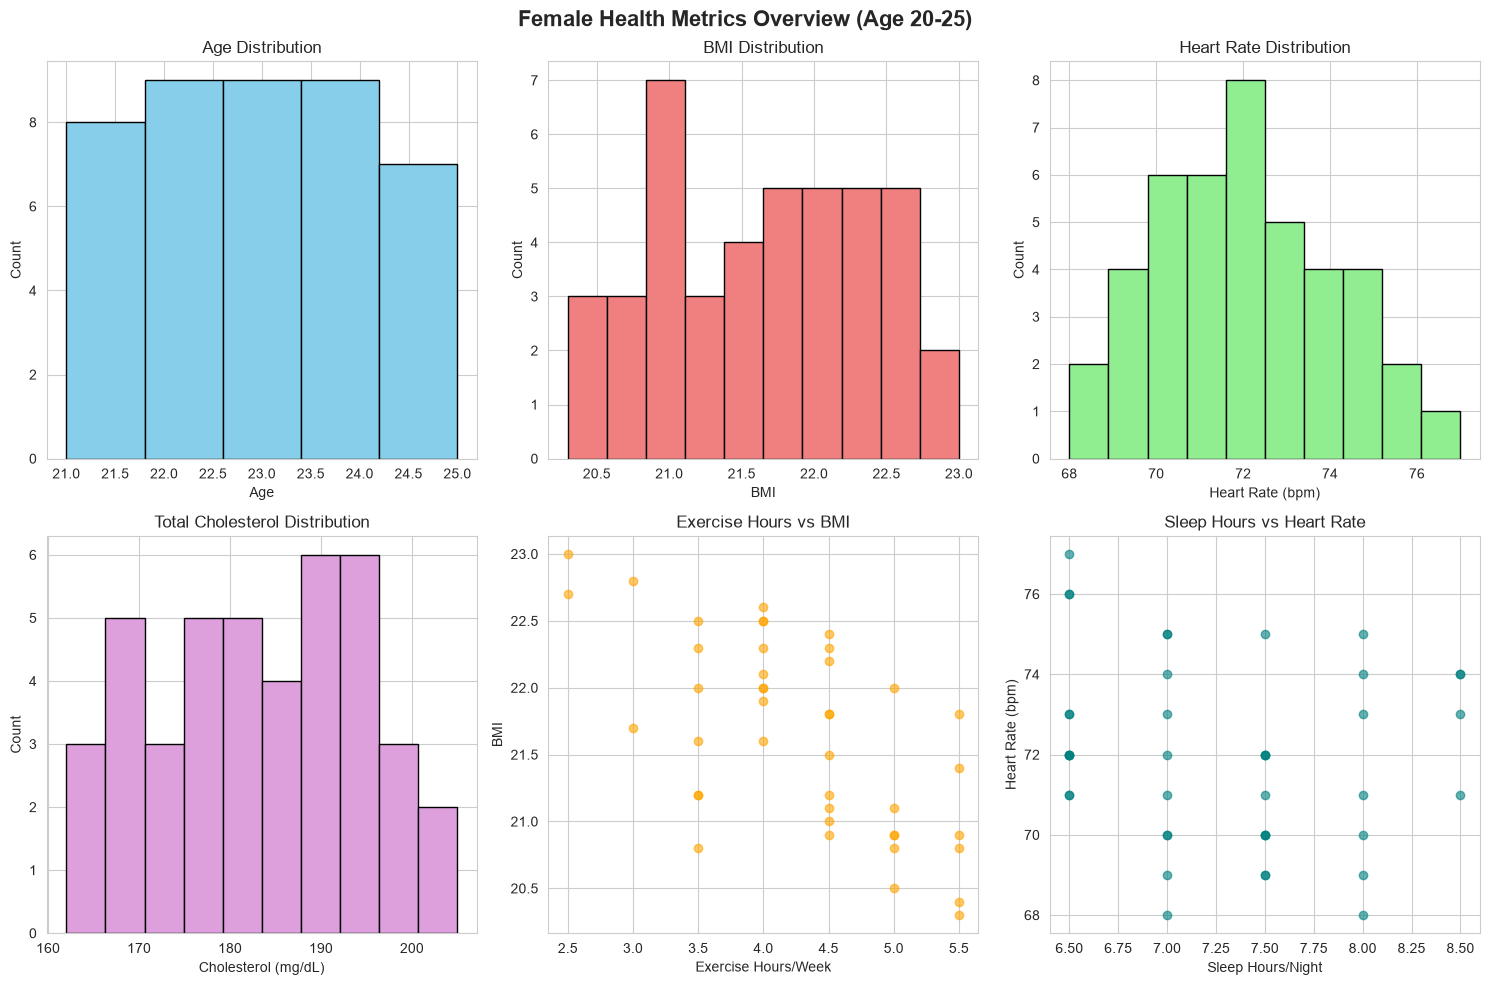

In [15]:
# Create a figure with multiple subplots
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Female Health Metrics Overview (Age 20-25)', fontsize=16, fontweight='bold')

# 1. Age distribution
axes[0, 0].hist(df['Age'], bins=5, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Age Distribution')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Count')

# 2. BMI distribution
axes[0, 1].hist(df['BMI'], bins=10, color='lightcoral', edgecolor='black')
axes[0, 1].set_title('BMI Distribution')
axes[0, 1].set_xlabel('BMI')
axes[0, 1].set_ylabel('Count')

# 3. Heart Rate distribution
axes[0, 2].hist(df['Heart_Rate'], bins=10, color='lightgreen', edgecolor='black')
axes[0, 2].set_title('Heart Rate Distribution')
axes[0, 2].set_xlabel('Heart Rate (bpm)')
axes[0, 2].set_ylabel('Count')

# 4. Total Cholesterol
axes[1, 0].hist(df['Total_Cholesterol'], bins=10, color='plum', edgecolor='black')
axes[1, 0].set_title('Total Cholesterol Distribution')
axes[1, 0].set_xlabel('Cholesterol (mg/dL)')
axes[1, 0].set_ylabel('Count')

# 5. Exercise vs BMI
axes[1, 1].scatter(df['Exercise_Hours_Per_Week'], df['BMI'], alpha=0.6, color='orange')
axes[1, 1].set_title('Exercise Hours vs BMI')
axes[1, 1].set_xlabel('Exercise Hours/Week')
axes[1, 1].set_ylabel('BMI')

# 6. Sleep vs Heart Rate
axes[1, 2].scatter(df['Sleep_Hours_Per_Night'], df['Heart_Rate'], alpha=0.6, color='teal')
axes[1, 2].set_title('Sleep Hours vs Heart Rate')
axes[1, 2].set_xlabel('Sleep Hours/Night')
axes[1, 2].set_ylabel('Heart Rate (bpm)')

plt.tight_layout()
plt.show()

## Correlation Analysis

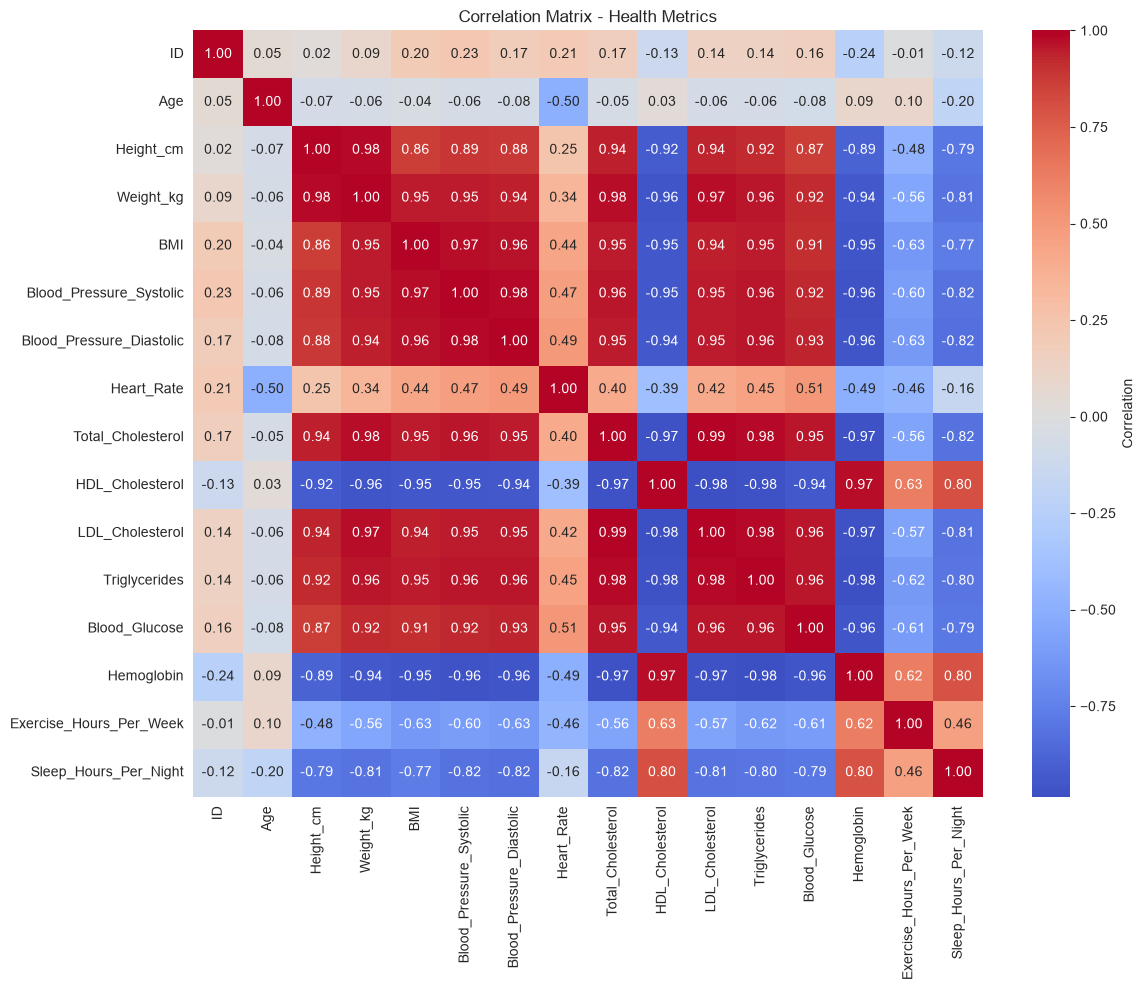

In [16]:
# Select numerical columns for correlation analysis
numeric_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numeric_cols].corr()

# Create a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar_kws={'label': 'Correlation'})
plt.title('Correlation Matrix - Health Metrics')
plt.tight_layout()
plt.show()

## Data Analysis & Insights

In [17]:
# Filter for specific ranges and get insights
normal_bmi = df[(df['BMI'] >= 18.5) & (df['BMI'] < 25)]
print(f"Women with normal BMI (18.5-25): {len(normal_bmi)}/{len(df)} ({len(normal_bmi)/len(df)*100:.1f}%)")

good_sleep = df[df['Sleep_Hours_Per_Night'] >= 7]
print(f"Women getting ≥7 hours sleep: {len(good_sleep)}/{len(df)} ({len(good_sleep)/len(df)*100:.1f}%)")

active = df[df['Exercise_Hours_Per_Week'] >= 4.5]
print(f"Women exercising ≥4.5 hours/week: {len(active)}/{len(df)} ({len(active)/len(df)*100:.1f}%)")

normal_glucose = df[df['Blood_Glucose'] < 100]
print(f"Women with normal fasting glucose (<100): {len(normal_glucose)}/{len(df)} ({len(normal_glucose)/len(df)*100:.1f}%)")

# Correlation between exercise and cholesterol
exercise_chol_corr = df['Exercise_Hours_Per_Week'].corr(df['Total_Cholesterol'])
print(f"\nCorrelation between exercise and cholesterol: {exercise_chol_corr:.3f}")

# Correlation between sleep and heart rate
sleep_hr_corr = df['Sleep_Hours_Per_Night'].corr(df['Heart_Rate'])
print(f"Correlation between sleep and heart rate: {sleep_hr_corr:.3f}")

Women with normal BMI (18.5-25): 42/42 (100.0%)
Women getting ≥7 hours sleep: 31/42 (73.8%)
Women exercising ≥4.5 hours/week: 22/42 (52.4%)
Women with normal fasting glucose (<100): 39/42 (92.9%)

Correlation between exercise and cholesterol: -0.561
Correlation between sleep and heart rate: -0.156


**Note on correlation**
A *negative correlation* means that as one variable increases, the other tends to decrease, and vice versa. The relationship is inverse and *positive correlation* is the opposite.

Negative correlation between exercise and cholesterol would mean: people who exercise more tend to have lower cholesterol levels.
Negative correlation between sleep and heart rate would mean: people who sleep more tend to have lower heart rates.
Correlation values range from -1 to +1:

-1 = perfect negative correlation (as one increases, the other always decreases)
0 = no correlation (variables are independent)
+1 = perfect positive correlation (as one increases, the other always increases)

Seaborn visualization examples

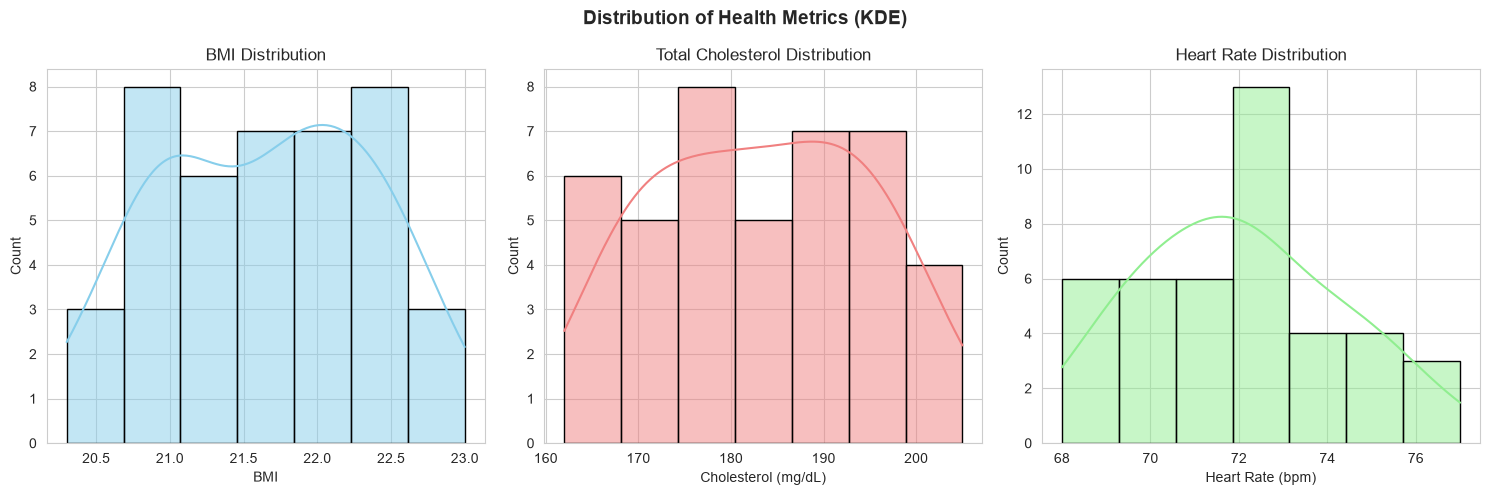

In [25]:
# Cell 1: Distribution plots with KDE
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Distribution of Health Metrics (KDE)', fontsize=14, fontweight='bold')

sns.histplot(data=df, x='BMI', kde=True, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('BMI Distribution')
axes[0].set_xlabel('BMI')

sns.histplot(data=df, x='Total_Cholesterol', kde=True, ax=axes[1], color='lightcoral', edgecolor='black')
axes[1].set_title('Total Cholesterol Distribution')
axes[1].set_xlabel('Cholesterol (mg/dL)')

sns.histplot(data=df, x='Heart_Rate', kde=True, ax=axes[2], color='lightgreen', edgecolor='black')
axes[2].set_title('Heart Rate Distribution')
axes[2].set_xlabel('Heart Rate (bpm)')

plt.tight_layout()
plt.show()

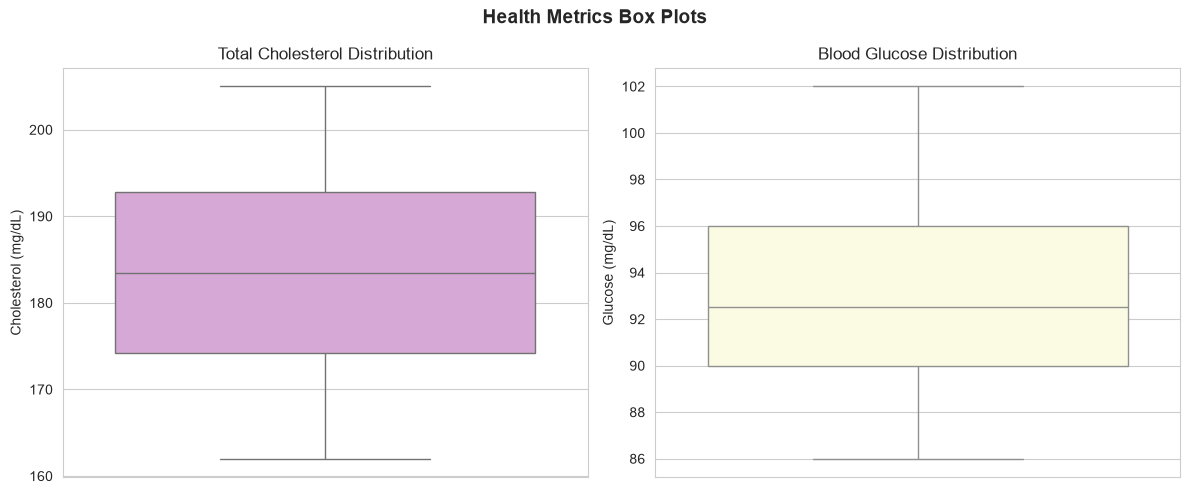

In [26]:
# Cell 2: Box plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Health Metrics Box Plots', fontsize=14, fontweight='bold')

sns.boxplot(data=df, y='Total_Cholesterol', ax=axes[0], color='plum')
axes[0].set_title('Total Cholesterol Distribution')
axes[0].set_ylabel('Cholesterol (mg/dL)')

sns.boxplot(data=df, y='Blood_Glucose', ax=axes[1], color='lightyellow')
axes[1].set_title('Blood Glucose Distribution')
axes[1].set_ylabel('Glucose (mg/dL)')

plt.tight_layout()
plt.show()

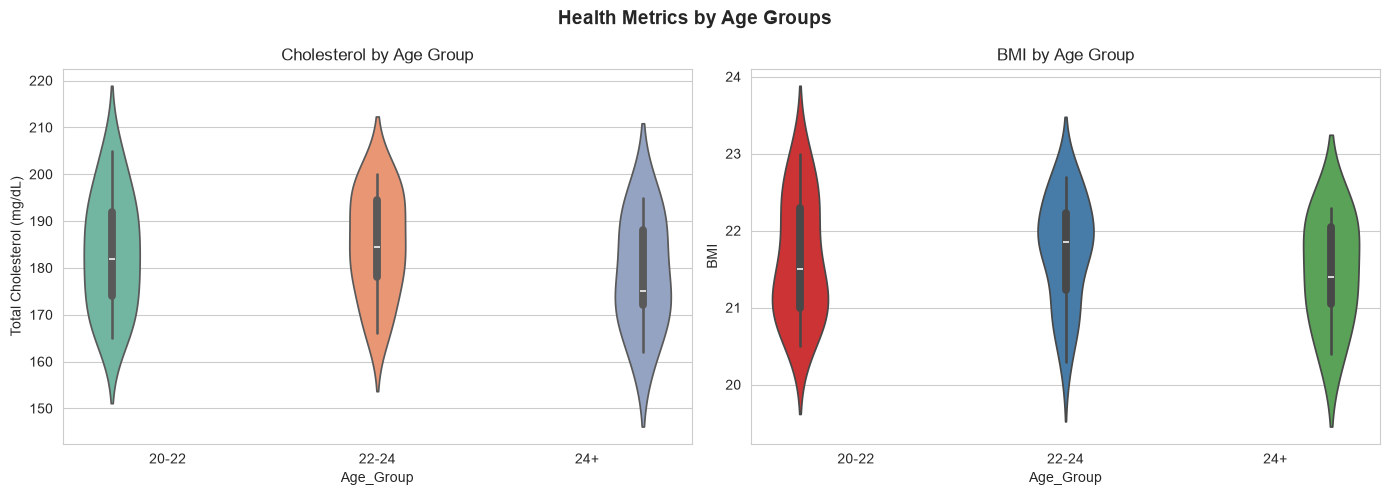

In [27]:
# Cell 3: Violin plots by age groups
df['Age_Group'] = pd.cut(df['Age'], bins=[20, 22, 24, 26], labels=['20-22', '22-24', '24+'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Health Metrics by Age Groups', fontsize=14, fontweight='bold')

sns.violinplot(data=df, x='Age_Group', y='Total_Cholesterol', hue='Age_Group', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Cholesterol by Age Group')
axes[0].set_ylabel('Total Cholesterol (mg/dL)')

sns.violinplot(data=df, x='Age_Group', y='BMI', hue='Age_Group', ax=axes[1], palette='Set1', legend=False)
axes[1].set_title('BMI by Age Group')
axes[1].set_ylabel('BMI')

plt.tight_layout()
plt.show()

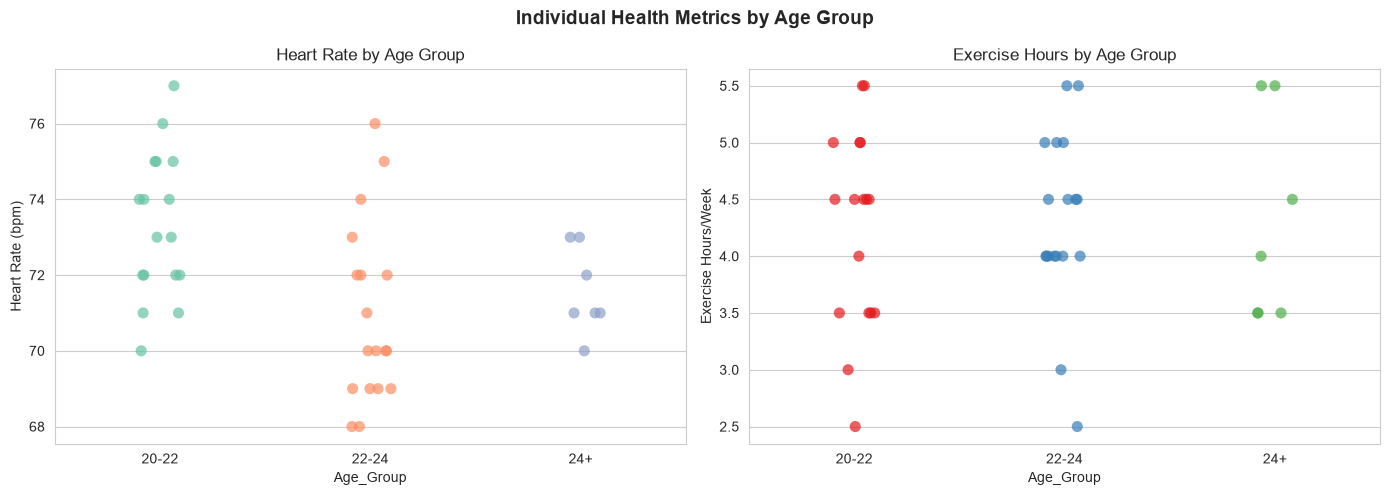

In [28]:
# Cell 5: Strip plots for individual data points
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Individual Health Metrics by Age Group', fontsize=14, fontweight='bold')

sns.stripplot(data=df, x='Age_Group', y='Heart_Rate', hue='Age_Group', ax=axes[0], size=8, alpha=0.7, jitter=True, palette='Set2', legend=False)
axes[0].set_title('Heart Rate by Age Group')
axes[0].set_ylabel('Heart Rate (bpm)')

sns.stripplot(data=df, x='Age_Group', y='Exercise_Hours_Per_Week', hue='Age_Group', ax=axes[1], size=8, alpha=0.7, jitter=True, palette='Set1', legend=False)
axes[1].set_title('Exercise Hours by Age Group')
axes[1].set_ylabel('Exercise Hours/Week')

plt.tight_layout()
plt.show()

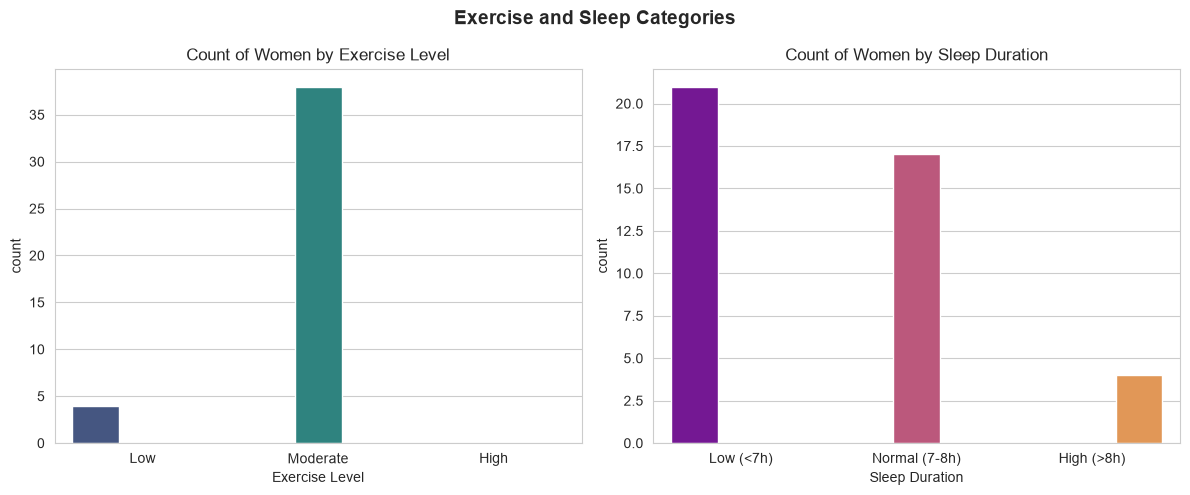

In [29]:
# Cell 6: Count plots for categorical distributions
df['Exercise_Level'] = pd.cut(df['Exercise_Hours_Per_Week'], bins=[0, 3, 6, 10], labels=['Low', 'Moderate', 'High'])
df['Sleep_Duration'] = pd.cut(df['Sleep_Hours_Per_Night'], bins=[6, 7, 8, 10], labels=['Low (<7h)', 'Normal (7-8h)', 'High (>8h)'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Exercise and Sleep Categories', fontsize=14, fontweight='bold')

sns.countplot(data=df, x='Exercise_Level', hue='Exercise_Level', ax=axes[0], palette='viridis', legend=False)
axes[0].set_title('Count of Women by Exercise Level')
axes[0].set_xlabel('Exercise Level')

sns.countplot(data=df, x='Sleep_Duration', hue='Sleep_Duration', ax=axes[1], palette='plasma', legend=False)
axes[1].set_title('Count of Women by Sleep Duration')
axes[1].set_xlabel('Sleep Duration')

plt.tight_layout()
plt.show()

KeyError: 'Height'

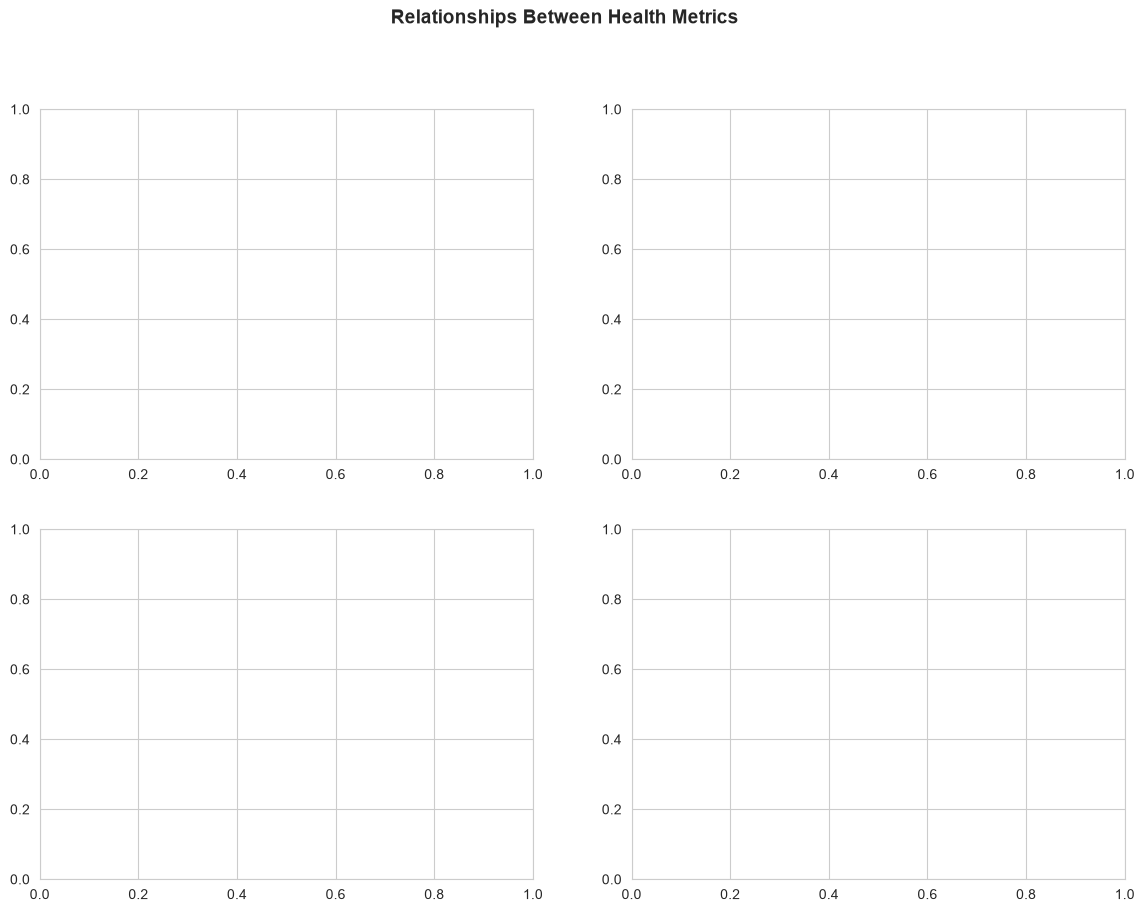

In [30]:
# Cell 4: Scatter plots with regression lines
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Relationships Between Health Metrics', fontsize=14, fontweight='bold')

sns.regplot(data=df, x='Height', y='BMI', ax=axes[0, 0], scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
axes[0, 0].set_title('Height vs BMI')

sns.regplot(data=df, x='Exercise_Hours_Per_Week', y='Total_Cholesterol', ax=axes[0, 1], scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
axes[0, 1].set_title('Exercise vs Total Cholesterol')

sns.regplot(data=df, x='Sleep_Hours_Per_Night', y='Heart_Rate', ax=axes[1, 0], scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
axes[1, 0].set_title('Sleep Hours vs Heart Rate')

sns.regplot(data=df, x='Age', y='Hemoglobin', ax=axes[1, 1], scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
axes[1, 1].set_title('Age vs Hemoglobin')

plt.tight_layout()
plt.show()